In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("/content/ML_Lab_Multiple_Linear_Regression_House_Prices.csv")

In [3]:
df.head()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_Metro_km,Parking,Floor,Balconies,Price_Lakhs
0,1726,2,2,0,14.1,1,10,3,168.54
1,2059,2,1,4,9.8,1,10,3,185.35
2,1460,4,4,15,8.0,1,0,3,183.25
3,1894,4,4,18,10.0,0,0,0,187.83
4,1730,1,1,3,6.8,1,1,2,158.35


In [4]:
features = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Age_years",
    "Distance_to_Metro_km",
    "Parking",
    "Floor",
    "Balconies"
]

X = df[features].values

y = df["Price_Lakhs"].values

In [5]:
print(df[features].describe())

         Area_sqft    Bedrooms   Bathrooms   Age_years  Distance_to_Metro_km  \
count   100.000000  100.000000  100.000000  100.000000            100.000000   
mean   1572.580000    2.970000    2.780000    9.940000              7.807000   
std     532.161652    1.473366    1.467355    6.499137              4.130602   
min     613.000000    1.000000    1.000000    0.000000              0.700000   
25%    1149.000000    1.750000    1.000000    4.000000              4.300000   
50%    1598.000000    3.000000    3.000000   10.500000              8.250000   
75%    2019.000000    4.000000    4.000000   16.000000             10.650000   
max    2499.000000    5.000000    5.000000   20.000000             14.700000   

          Parking      Floor   Balconies  
count  100.000000  100.00000  100.000000  
mean     0.720000    4.44000    1.400000  
std      0.451261    3.27932    1.073087  
min      0.000000    0.00000    0.000000  
25%      0.000000    1.00000    0.000000  
50%      1.000000    

In [6]:
#Experiment 1: Gradient Descent Without Scaling

m = len(y)
weights = np.zeros(X.shape[1])
bias = 0
learning_rate = 0.0000001
iterations = 1000

In [8]:
cost_history = []
for i in range(iterations):
# Prediction
  y_pred = X @ weights + bias
# Error
  error = y_pred - y
# Individual loss
  individual_loss = 0.5 * (error ** 2)
# Cost
  cost = np.mean(individual_loss)
# Store cost
  cost_history.append(cost)
# Gradients
  dw = (1/m) * (X.T @ error)
  db = (1/m) * np.sum(error)
# Parameter update
  weights = weights - learning_rate * dw
  bias = bias - learning_rate * db

In [9]:
print("Final Cost:", cost_history[-1])

Final Cost: 501.1409858199032


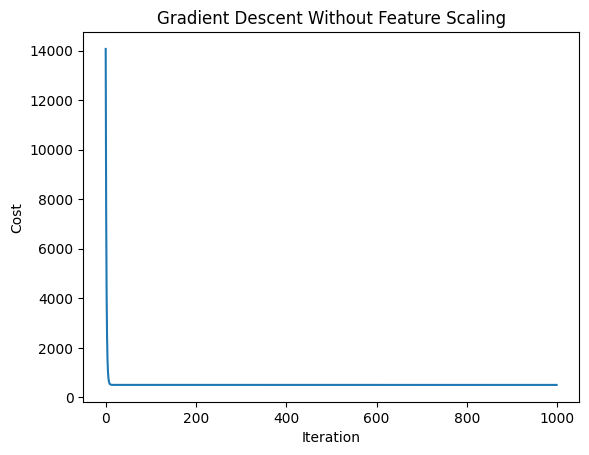

In [10]:
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
"Gradient Descent Without Feature Scaling"
)
plt.show()

In [11]:
#Experiment 2: Gradient Descent With Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.28974824 -0.66167301 -0.53424658 -1.53713872  1.53118203  0.62360956
   1.70401496  1.4985373 ]
 [ 0.91865036 -0.66167301 -1.21917808 -0.91857183  0.48492703  0.62360956
   1.70401496  1.4985373 ]
 [-0.21261802  0.70260124  0.83561644  0.78248712  0.04695982  0.62360956
  -1.36076014  1.4985373 ]
 [ 0.60703219  0.70260124  0.83561644  1.24641229  0.53359005 -1.60356745
  -1.36076014 -1.31122014]
 [ 0.29730262 -1.34381014 -1.21917808 -1.07321356 -0.24501832  0.62360956
  -1.05428263  0.56195149]]


In [12]:
weights = np.zeros(X_scaled.shape[1])
bias = 0

In [13]:
learning_rate = 0.01
iterations = 1000

In [14]:
cost_history_scaled = []
for i in range(iterations):
# Prediction
  y_pred = X_scaled @ weights + bias
# Error
  error = y_pred - y
# Individual loss
  individual_loss = 0.5 * (error ** 2)
# Cost
  cost = np.mean(individual_loss)
# Store cost
  cost_history_scaled.append(cost)
# Gradients
  dw = (1/m) * (X_scaled.T @ error)
  db = (1/m) * np.sum(error)
# Parameter update
  weights = weights - learning_rate * dw
  bias = bias - learning_rate * db

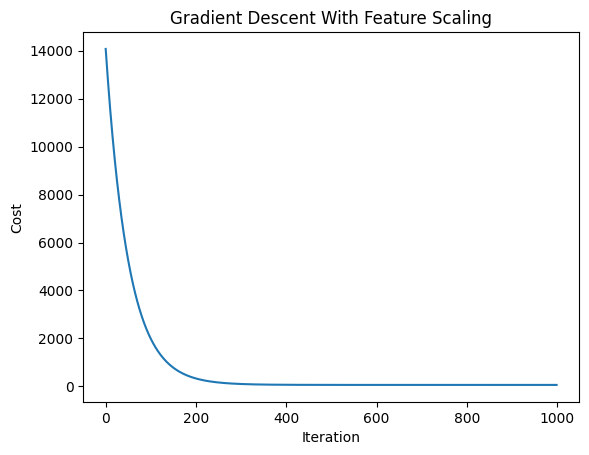

In [15]:
plt.plot(cost_history_scaled)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
"Gradient Descent With Feature Scaling"
)
plt.show()

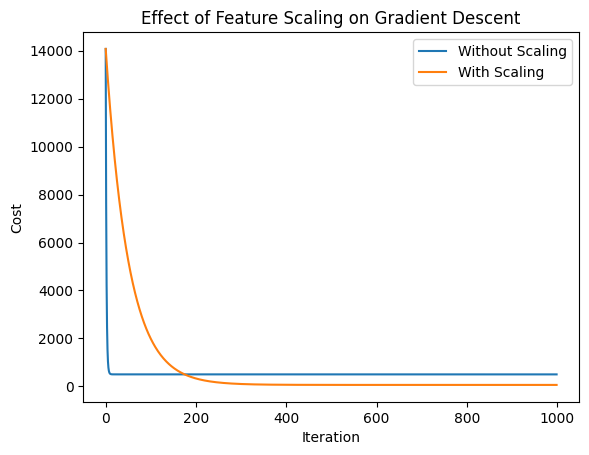

In [16]:
#Comparison

plt.plot(
cost_history,
label="Without Scaling"
)
plt.plot(
cost_history_scaled,
label="With Scaling"
)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title(
"Effect of Feature Scaling on Gradient Descent"
)
plt.legend()
plt.show()